# Project 2.2 Multimodal Prediction of Pet Adoption Speed

## Section 1: Data Exploration and Feature Extraction
* Data Sources:
   * PetFinder.my Adoption Prediction, https://www.kaggle.com/competitions/petfinder-adoption-prediction. Addison Howard, MichaelApers, and Mongrel Jedi. PetFinder.my Adoption Prediction. Kaggle, 2018.
    
* Changes from the proposal:
   * Individual work: the group proposal is implemented to individual; all analyses done in this notebook are my own.
   * Compute: feature extraction runs locally since offline freindly, (Apple M4 Max, 36GB RAM, MPS) instead of the Colab T4 used for the feasibility test.
   * Image encoder: ResNet-50 (2048-d) instead of the ResNet18 (512-d) tested in the proposal, because local compute made the larger model affordable.
   * Text encoder: multilingual BERT as proposed, but the maximum length is raised from 128 to 256 tokens (21.5% of descriptions exceed 128, 5.5% exceed 256).
   * Attention fusion: implemented (the proposal listed it as "if time allows").
   * Data split: stratified 70/15/15 split at group level, so identical images or descriptions never fall in different splits (avoids leakage).
   * Added analyses: bootstrap confidence intervals, per-class and subgroup results, and post-hoc class re-weighting to reduce the class imbalance problem.
   * Privacy: phone numbers and e-mail addresses are masked with regular expressions before text encoding; names inside descriptions are not removed.

In [1]:
### import relevant libraries
# Dependencies (install once if missing):
#   pip install xgboost torch torchvision transformers scikit-learn matplotlib seaborn
import os
import re
import json
import time
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             cohen_kappa_score, classification_report, confusion_matrix, log_loss)
from scipy.optimize import minimize

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision import models
import transformers
from transformers import AutoTokenizer, AutoModel

warnings.filterwarnings("ignore")

SEED = 42  # reproducible by fixing random seeds
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")

# Use the Apple GPU (MPS) or CUDA if available, otherwise the CPU
DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")

DATA = Path("data")                       # Kaggle data folder, placed next to this notebook
CLASS_NAMES = ["0", "1", "2", "3", "4"]   # AdoptionSpeed classes

print("torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| transformers", transformers.__version__, "| xgboost", xgb.__version__, "| device:", DEVICE)

torch 2.8.0 | torchvision 0.23.0 | transformers 5.20.0 | xgboost 3.4.1 | device: mps


In [40]:
#Load the dataset
train = pd.read_csv(next(DATA.rglob("train.csv")))
print(train.shape)
print(train.dtypes)

(14993, 24)
Type               int64
Name              object
Age                int64
Breed1             int64
Breed2             int64
Gender             int64
Color1             int64
Color2             int64
Color3             int64
MaturitySize       int64
FurLength          int64
Vaccinated         int64
Dewormed           int64
Sterilized         int64
Health             int64
Quantity           int64
Fee                int64
State              int64
RescuerID         object
VideoAmt           int64
Description       object
PetID             object
PhotoAmt         float64
AdoptionSpeed      int64
dtype: object


### Task 1: Data Exploration and Quality Assessment

In [ ]:
# Image exploration
# Profile image per pet = the image with the smallest index (normally "-1")
imgs = {}
for p in (DATA / "train_images").glob("*.jpg"):
    pet, idx = p.stem.rsplit("-", 1)
    imgs.setdefault(pet, []).append((int(idx), p))
train["image_path"] = train["PetID"].map(lambda pet: str(min(imgs[pet])[1]) if pet in imgs else None)
train["n_images"] = train["PetID"].map(lambda pet: len(imgs.get(pet, [])))

# 4 random example profile images per AdoptionSpeed class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(5, 4, figsize=(10, 13))
for c in range(5):
    sub = train[(train["AdoptionSpeed"] == c) & train["image_path"].notna()]
    for j, path in enumerate(rng.choice(sub["image_path"].values, 4, replace=False)):
        axes[c, j].imshow(Image.open(path))
        axes[c, j].axis("off")
        axes[c, j].set_title(f"class {c}", fontsize=9)
fig.suptitle("Example profile images by AdoptionSpeed class")
plt.tight_layout()
plt.show()

# Image size and brightness statistics on a random sample of 500 profile images
sample = train.dropna(subset=["image_path"]).sample(500, random_state=SEED)
stats = []
for path in sample["image_path"]:
    im = Image.open(path)
    stats.append((im.width, im.height, np.asarray(im.convert("L")).mean()))
stats = pd.DataFrame(stats, columns=["width", "height", "brightness"])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["width", "height", "brightness"]):
    sns.histplot(stats[col], bins=30, ax=a, color="steelblue")
    a.set(title=f"Image {col} (500 sampled profile images)", xlabel=col, ylabel="Number of images")
plt.tight_layout()
plt.show()
print("images per pet: mean %.1f, max %d" % (train["n_images"].mean(), train["n_images"].max()))

           Age      Fee  Quantity  VideoAmt  PhotoAmt
count  14993.0  14993.0   14993.0   14993.0   14993.0
mean      10.5     21.3       1.6       0.1       3.9
std       18.2     78.4       1.5       0.3       3.5
min        0.0      0.0       1.0       0.0       0.0
25%        2.0      0.0       1.0       0.0       2.0
50%        3.0      0.0       1.0       0.0       3.0
75%       12.0      0.0       1.0       0.0       5.0
max      255.0   3000.0      20.0       8.0      30.0


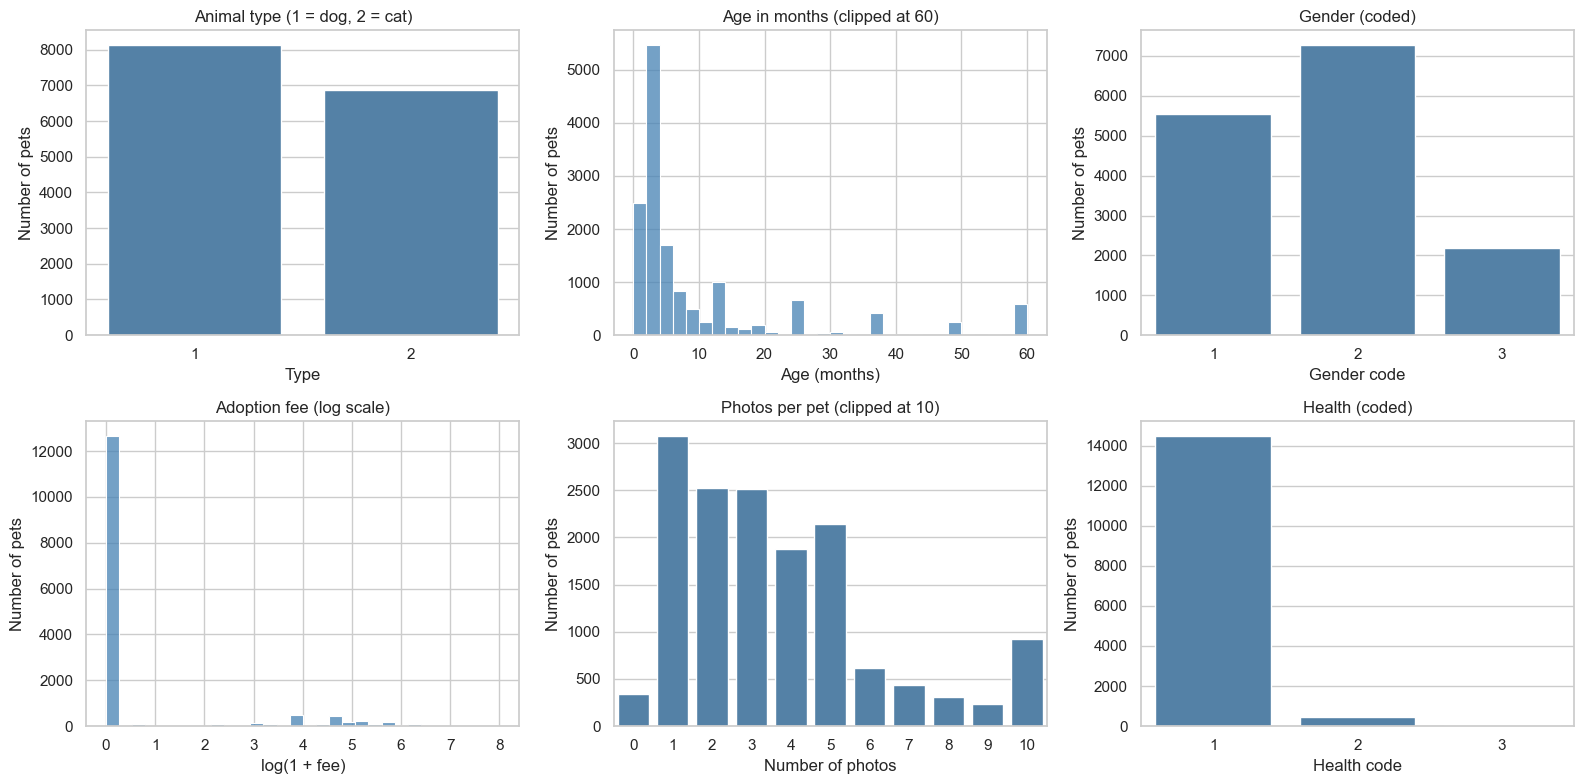

In [34]:
#Tabular exploration
num_cols = ["Age", "Fee", "Quantity", "VideoAmt", "PhotoAmt"]
print(train[num_cols].describe().round(1))

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(x="Type", data=train, ax=ax[0, 0], color="steelblue")
ax[0, 0].set(title="Animal type (1 = dog, 2 = cat)", xlabel="Type", ylabel="Number of pets")
sns.histplot(train["Age"].clip(upper=60), bins=30, ax=ax[0, 1], color="steelblue")
ax[0, 1].set(title="Age in months (clipped at 60)", xlabel="Age (months)", ylabel="Number of pets")
sns.countplot(x="Gender", data=train, ax=ax[0, 2], color="steelblue")
ax[0, 2].set(title="Gender (coded)", xlabel="Gender code", ylabel="Number of pets")
sns.histplot(np.log1p(train["Fee"]), bins=30, ax=ax[1, 0], color="steelblue")
ax[1, 0].set(title="Adoption fee (log scale)", xlabel="log(1 + fee)", ylabel="Number of pets")
sns.countplot(x=train["PhotoAmt"].clip(upper=10).astype(int), ax=ax[1, 1], color="steelblue")
ax[1, 1].set(title="Photos per pet (clipped at 10)", xlabel="Number of photos", ylabel="Number of pets")
sns.countplot(x="Health", data=train, ax=ax[1, 2], color="steelblue")
ax[1, 2].set(title="Health (coded)", xlabel="Health code", ylabel="Number of pets")
plt.tight_layout()
plt.show()

count    14993.0
mean        63.0
std         69.3
min          0.0
25%         21.0
50%         44.0
75%         81.0
max       1257.0
Name: desc_words, dtype: float64
descriptions with >5% non-ASCII characters: 134


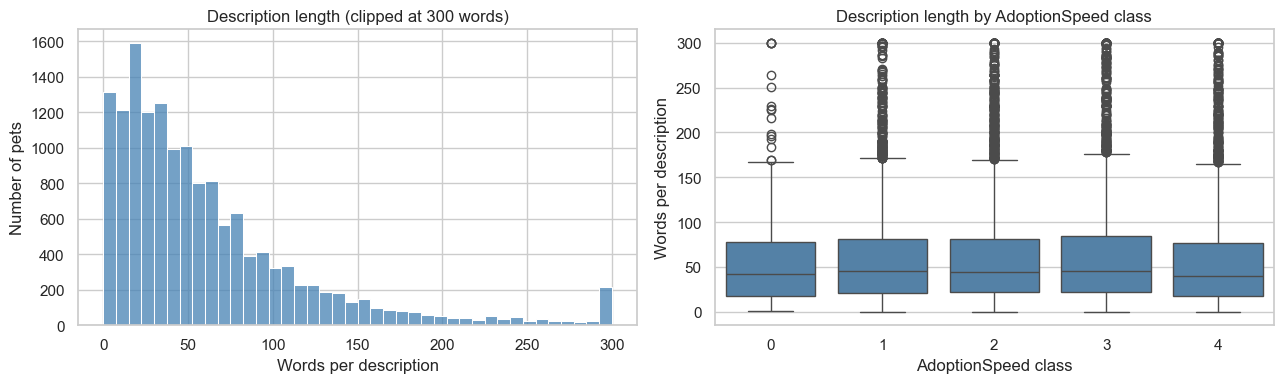

In [31]:
#Text exploration
desc = train["Description"].fillna("")
train["desc_words"] = desc.str.split().str.len()

train["non_ascii_share"] = desc.map(lambda s: sum(ord(ch) > 127 for ch in s) / max(len(s), 1))
print(train["desc_words"].describe().round(1))
print("descriptions with >5% non-ASCII characters:", (train["non_ascii_share"] > 0.05).sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["desc_words"].clip(upper=300), bins=40, ax=ax[0], color="steelblue")
ax[0].set(title="Description length (clipped at 300 words)", xlabel="Words per description", ylabel="Number of pets")
sns.boxplot(data=train.assign(words=train["desc_words"].clip(upper=300)),
            x="AdoptionSpeed", y="words", ax=ax[1], color="steelblue")
ax[1].set(title="Description length by AdoptionSpeed class", xlabel="AdoptionSpeed class", ylabel="Words per description")
plt.tight_layout()
plt.show()

In [6]:
# Data quality: missing values, ranges, duplicates, consistency
# Missing / empty values
print("missing values:\n", train.isna().sum()[lambda s: s > 0])
print("empty descriptions (0 words):", (train["desc_words"] == 0).sum())

# Value ranges
print("\nnegative Age / Fee:", (train["Age"] < 0).sum(), (train["Fee"] < 0).sum())
print("AdoptionSpeed values:", sorted(train["AdoptionSpeed"].unique().tolist()))

# Duplicates: whole rows, exact profile images, exact descriptions
train["img_hash"] = train["image_path"].map(
    lambda f: hashlib.md5(Path(f).read_bytes()).hexdigest() if isinstance(f, str) else None)
train["img_group"] = train["img_hash"].factorize()[0]   # identical image -> same group id (-1 = no image)
dup_img = train.dropna(subset=["img_hash"]).groupby("img_hash").size()
dup_desc = train.loc[train["desc_words"] > 0, "Description"].duplicated(keep=False)
print("\nduplicated rows:", train.duplicated().sum())
print("duplicate-image groups:", (dup_img > 1).sum(), "| pets in them:", dup_img[dup_img > 1].sum())
print("pets sharing an exact description with another pet:", dup_desc.sum())

# Consistency checks
print("\nPhotoAmt vs actual number of images, mismatches:", (train["PhotoAmt"] != train["n_images"]).sum())
breeds = pd.read_csv(DATA / "breed_labels.csv")
breed_type = dict(zip(breeds["BreedID"], breeds["Type"]))
bad = (train["Breed1"] != 0) & (train["Breed1"].map(breed_type) != train["Type"])
print("Breed1 belonging to the other animal type:", bad.sum())
print("Breed2 set while Breed1 is 0:", ((train["Breed2"] != 0) & (train["Breed1"] == 0)).sum())

missing values:
 Name           1265
Description      13
image_path      341
dtype: int64
empty descriptions (0 words): 13

negative Age / Fee: 0 0
AdoptionSpeed values: [0, 1, 2, 3, 4]

duplicated rows: 0
duplicate-image groups: 72 | pets in them: 146
pets sharing an exact description with another pet: 1271

PhotoAmt vs actual number of images, mismatches: 0
Breed1 belonging to the other animal type: 12
Breed2 set while Breed1 is 0: 5


In [7]:
# Privacy check: phone numbers and e-mail addresses in descriptions (promised in the proposal)
EMAIL = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
PHONE = re.compile(r"(?<!\w)\+?\d(?:[\s-]?\d){8,12}(?!\d)")     # 9-13 digits, optional spaces or hyphens

def mask_pii(text):
    return PHONE.sub("[PHONE]", EMAIL.sub("[EMAIL]", text))

desc = train["Description"].fillna("")
has_email, has_phone = desc.str.contains(EMAIL), desc.str.contains(PHONE)
print("descriptions with an e-mail address:", has_email.sum(),
      "| with a phone number:", has_phone.sum(),
      "| either:", (has_email | has_phone).sum())
print("masking changes", (desc.map(mask_pii) != desc).sum(), "descriptions before text encoding")

descriptions with an e-mail address: 0 | with a phone number: 4 | either: 4
masking changes 4 descriptions before text encoding


In [8]:
# Preprocessing
# all three modalities
keep = train["image_path"].notna() & (train["desc_words"] > 0)
df = train[keep].reset_index(drop=True)
print("pets kept:", len(df), "of", len(train), f"({len(df) / len(train):.2%})")

# Labels, shared by all models
y = df["AdoptionSpeed"].values

# Text
texts = df["Description"].str.strip().map(mask_pii).tolist()

# Tabular
cat_cols = ["Type", "Gender", "Color1", "Color2", "Color3", "MaturitySize", "FurLength",
            "Vaccinated", "Dewormed", "Sterilized", "Health", "State"]
num = df[["Age", "Fee", "Quantity", "VideoAmt", "PhotoAmt"]].copy()
num["Age"], num["Fee"] = np.log1p(num["Age"]), np.log1p(num["Fee"])
for c in ["Breed1", "Breed2"]:
    num[c + "_freq"] = df[c].map(df[c].value_counts(normalize=True))
tab = pd.concat([num, pd.get_dummies(df[cat_cols].astype(str), dtype=float)], axis=1)
X_tab = tab.values.astype(np.float32)
print("tabular matrix:", X_tab.shape, "| texts:", len(texts), "| labels:", y.shape)

pets kept: 14640 of 14993 (97.65%)
tabular matrix: (14640, 65) | texts: 14640 | labels: (14640,)


In [ ]:
# Image preprocessing: RGB -> resize -> centre crop 224x224 -> ImageNet normalisation
weights = models.ResNet50_Weights.IMAGENET1K_V2
preprocess = weights.transforms()

example = Image.open(df["image_path"][0]).convert("RGB")
tensor = preprocess(example)
mean = torch.tensor(preprocess.mean).view(3, 1, 1)
std = torch.tensor(preprocess.std).view(3, 1, 1)
shown = (tensor * std + mean).clamp(0, 1).permute(1, 2, 0)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(example)
ax[0].set_title(f"Original ({example.width}x{example.height})")
ax[1].imshow(shown)
ax[1].set_title("After resize and centre crop (224x224)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### Task 2: Feature Extraction

In [10]:
# Visual features
extract_time = {}
resnet = models.resnet50(weights=weights)
resnet.fc = nn.Identity()          # drop the 1000-class layer, keep the pooled 2048-d vector
resnet = resnet.to(DEVICE).eval()  # eval mode: no dropout, batch-norm statistics frozen

class ImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return preprocess(Image.open(self.paths[i]).convert("RGB"))

t0 = time.time()
feats = []
with torch.no_grad():              # feature extraction only, no training
    for x in DataLoader(ImageDataset(df["image_path"].tolist()), batch_size=64, num_workers=0):
        feats.append(resnet(x.to(DEVICE)).cpu().numpy())
X_vis = np.concatenate(feats)
extract_time["visual"] = time.time() - t0
print("visual features:", X_vis.shape, "| time: %.1f s" % extract_time["visual"])

visual features: (14640, 2048) | time: 52.5 s


In [11]:
#Text features
name = "bert-base-multilingual-cased"
tok = AutoTokenizer.from_pretrained(name)
bert = AutoModel.from_pretrained(name).to(DEVICE).eval()
MAX_LEN = 256                      # raised from 128 in the proposal test: long descriptions lose less text

# How many descriptions exceed the token limit?
n_tok = np.array([len(ids) for ids in tok(texts, truncation=False)["input_ids"]])
print("descriptions over 128 tokens: %.1f%% | over %d tokens: %.1f%%"
      % (100 * (n_tok > 128).mean(), MAX_LEN, 100 * (n_tok > MAX_LEN).mean()))

t0 = time.time()
out = []
with torch.no_grad():
    for i in range(0, len(texts), 64):
        b = tok(texts[i:i + 64], padding=True, truncation=True, max_length=MAX_LEN,
                return_tensors="pt").to(DEVICE)
        h = bert(**b).last_hidden_state                     # (batch, tokens, 768): one vector per token
        m = b["attention_mask"].unsqueeze(-1).float()       # 1 for real tokens, 0 for padding
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())   # average over real tokens only
X_txt = np.concatenate(out)
extract_time["text"] = time.time() - t0
print("text features:", X_txt.shape, "| time: %.1f s" % extract_time["text"])

W1106 12:55:35.706000 46618 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (550 > 512). Running this sequence through the model will result in indexing errors


descriptions over 128 tokens: 21.5% | over 256 tokens: 5.5%
text features: (14640, 768) | time: 107.8 s


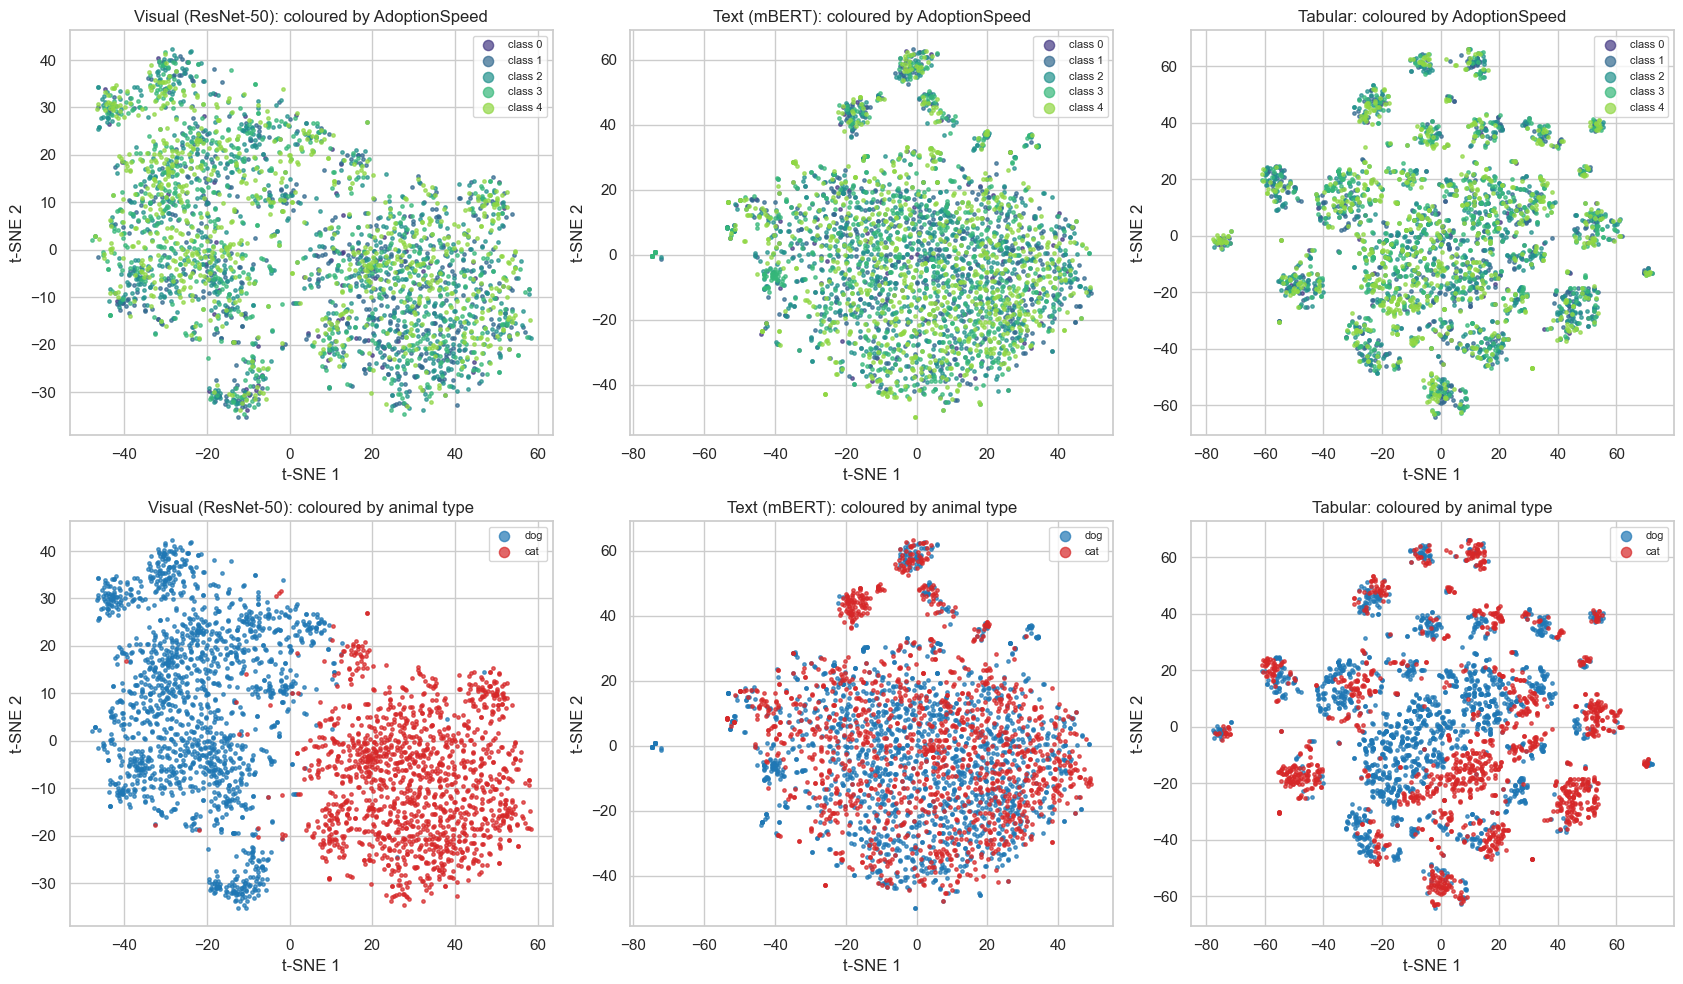

In [12]:
#Tabular features, saving, and t-SNE of each modality
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# The tabular "features" are the cleaned 65 columns themselves (no extraction step)
extract_time["tabular"] = 0.0
os.makedirs("features", exist_ok=True)
np.save("features/X_vis.npy", X_vis); np.save("features/X_txt.npy", X_txt); np.save("features/X_tab.npy", X_tab)
json.dump(extract_time, open("features/extract_time.json", "w"))

rng = np.random.default_rng(SEED)
idx = rng.choice(len(df), 3000, replace=False)
feats = {"Visual (ResNet-50)": X_vis, "Text (mBERT)": X_txt, "Tabular": X_tab}
emb = {}
for key, X in feats.items():
    Z = StandardScaler().fit_transform(X[idx])
    Z = PCA(n_components=min(50, Z.shape[1]), random_state=SEED).fit_transform(Z)
    emb[key] = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(Z)

palette = sns.color_palette("viridis", 5)
animal = df["Type"].values[idx]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for j, (key, E) in enumerate(emb.items()):
    for c in range(5):                                   # top row: coloured by AdoptionSpeed
        m = y[idx] == c
        axes[0, j].scatter(E[m, 0], E[m, 1], s=6, alpha=0.7, color=palette[c], label=f"class {c}")
    axes[0, j].set(title=f"{key}: coloured by AdoptionSpeed", xlabel="t-SNE 1", ylabel="t-SNE 2")
    axes[0, j].legend(markerscale=3, fontsize=8)
    for t, lab, col in [(1, "dog", "tab:blue"), (2, "cat", "tab:red")]:   # bottom row: by animal type
        m = animal == t
        axes[1, j].scatter(E[m, 0], E[m, 1], s=6, alpha=0.7, color=col, label=lab)
    axes[1, j].set(title=f"{key}: coloured by animal type", xlabel="t-SNE 1", ylabel="t-SNE 2")
    axes[1, j].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
# Build Group ID
parent = list(range(len(df)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
for values in [df["img_hash"].values, np.array(texts)]:
    first = {}
    for i, v in enumerate(values):
        if v in first:
            union(i, first[v])
        else:
            first[v] = i
df["group"] = [find(i) for i in range(len(df))]
size = df.groupby("group")["group"].transform("size")
print("groups:", df["group"].nunique(), "| pets in multi-pet groups:", (size > 1).sum(),
      "| largest group:", size.max())

groups: 13668 | pets in multi-pet groups: 1317 | largest group: 164


metric                QWK  accuracy  macro F1
modality                                     
Tabular             0.295     0.377     0.285
Text (mBERT)        0.131     0.318     0.265
Visual (ResNet-50)  0.179     0.302     0.252


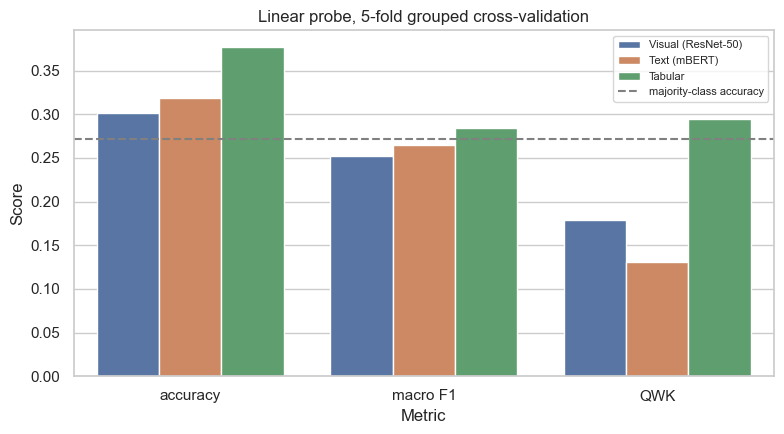

In [14]:
# Linear probe
from sklearn.model_selection import StratifiedGroupKFold
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for key, X in feats.items():
    accs, f1s, qwks = [], [], []
    for tr, te in skf.split(X, y, groups=df["group"]):
        sc = StandardScaler().fit(X[tr])                      # scaler fitted on the training folds only
        clf = LogisticRegression(C=0.1, max_iter=500).fit(sc.transform(X[tr]), y[tr])
        p = clf.predict(sc.transform(X[te]))
        accs.append(accuracy_score(y[te], p))
        f1s.append(f1_score(y[te], p, average="macro"))
        qwks.append(cohen_kappa_score(y[te], p, weights="quadratic"))
    rows += [(key, "accuracy", np.mean(accs), np.std(accs)),
             (key, "macro F1", np.mean(f1s), np.std(f1s)),
             (key, "QWK", np.mean(qwks), np.std(qwks))]
probe = pd.DataFrame(rows, columns=["modality", "metric", "mean", "std"])
print(probe.pivot(index="modality", columns="metric", values="mean").round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=probe, x="metric", y="mean", hue="modality", ax=ax)
ax.axhline(y.tolist().count(4) / len(y), color="grey", linestyle="--", label="majority-class accuracy")
ax.set(title="Linear probe, 5-fold grouped cross-validation", xlabel="Metric", ylabel="Score")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Section 2: Fusion Implementation
### Task 3: Data Splitting

In [15]:
# Split: stratified 70/15/15
rng = np.random.default_rng(SEED)
grp = df.groupby("group").agg(cls=("AdoptionSpeed", "first"), n=("PetID", "size"))
group_split = {}
for cls, sub in grp.groupby("cls"):
    order = rng.permutation(sub.index.values)                  # shuffle groups within a class
    cum = np.cumsum(sub.loc[order, "n"].values) / sub["n"].sum()
    for g, c in zip(order, cum):
        group_split[g] = "train" if c <= 0.70 else ("val" if c <= 0.85 else "test")
df["split"] = df["group"].map(group_split)

# Check sizes, class shares and leakage
summary = df.groupby("split")["AdoptionSpeed"].value_counts(normalize=True).unstack().round(3)
summary.insert(0, "n", df["split"].value_counts())
print(summary.loc[["train", "val", "test"]])
print("a group spans two splits:", (df.groupby("group")["split"].nunique() > 1).sum())
print("identical images shared between splits:", (df.groupby("img_hash")["split"].nunique() > 1).sum())
print("identical descriptions shared between splits:",
      (df.assign(text=texts).groupby("text")["split"].nunique() > 1).sum())

# Standardise each modality with statistics from the training split only
raw = {"visual": X_vis, "text": X_txt, "tabular": X_tab}
masks = {s: (df["split"] == s).values for s in ["train", "val", "test"]}
data = {m: {} for m in raw}
for m, X in raw.items():
    scaler = StandardScaler().fit(X[masks["train"]])           # fitted on training data only
    for s in masks:
        data[m][s] = scaler.transform(X[masks[s]]).astype(np.float32)
labels = {s: y[masks[s]] for s in masks}
for m in data:
    print(m, {s: v.shape for s, v in data[m].items()})
df.to_csv("pets_split.csv", index=False)

AdoptionSpeed      n      0      1      2      3      4
split                                                  
train          10240  0.026  0.217  0.267  0.216  0.273
val             2073  0.027  0.164  0.294  0.234  0.281
test            2327  0.026  0.210  0.280  0.227  0.257
a group spans two splits: 0
identical images shared between splits: 0
identical descriptions shared between splits: 0
visual {'train': (10240, 2048), 'val': (2073, 2048), 'test': (2327, 2048)}
text {'train': (10240, 768), 'val': (2073, 768), 'test': (2327, 768)}
tabular {'train': (10240, 65), 'val': (2073, 65), 'test': (2327, 65)}


### Task 4: Fusion implementation

In [16]:
#Early fusion
def metrics(y_true, proba):
    """Several metrics at once: accuracy, macro / weighted F1, quadratic weighted kappa, log loss."""
    pred = proba.argmax(1)
    return {"accuracy": accuracy_score(y_true, pred),
            "macro F1": f1_score(y_true, pred, average="macro"),
            "weighted F1": f1_score(y_true, pred, average="weighted"),
            "QWK": cohen_kappa_score(y_true, pred, weights="quadratic"),
            "log loss": log_loss(y_true, proba, labels=list(range(5)))}

class EarlyFusionClassifier:
    """Concatenate visual | text | tabular features and train a single XGBoost model."""
    def __init__(self, **params):
        self.params = dict(n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.3, early_stopping_rounds=30,
                           objective="multi:softprob", eval_metric="mlogloss",
                           tree_method="hist", random_state=SEED, n_jobs=-1)
        self.params.update(params)

    @staticmethod
    def _concat(d, split):
        return np.hstack([d["visual"][split], d["text"][split], d["tabular"][split]])

    def fit(self, data, labels):
        self.model = xgb.XGBClassifier(**self.params)
        self.model.fit(self._concat(data, "train"), labels["train"],
                       eval_set=[(self._concat(data, "val"), labels["val"])], verbose=False)
        return self

    def predict_proba(self, data, split):
        return self.model.predict_proba(self._concat(data, split))

t0 = time.time()
early = EarlyFusionClassifier().fit(data, labels)
time_early = time.time() - t0
print("best number of trees:", early.model.best_iteration + 1, "| training time: %.1f s" % time_early)
print(pd.DataFrame({s: metrics(labels[s], early.predict_proba(data, s)) for s in ["train", "val"]}).round(3))

best number of trees: 230 | training time: 37.8 s
             train    val
accuracy     0.823  0.397
macro F1     0.842  0.298
weighted F1  0.822  0.377
QWK          0.787  0.369
log loss     0.884  1.340


In [17]:
# Early fusion(Weight compare)
configs = {
    "depth 2": dict(max_depth=2),
    "depth 4": dict(max_depth=4),
    "depth 6": dict(max_depth=6),
    "depth 4 + stronger regularisation": dict(max_depth=4, min_child_weight=10, reg_lambda=10),
    "depth 2, up to 1000 trees (chosen)": dict(max_depth=2, n_estimators=1000),
}
rows, early_models = [], {}
for cfg_name, p in configs.items():
    t0 = time.time()
    m = EarlyFusionClassifier(**p).fit(data, labels)
    dt = time.time() - t0
    early_models[cfg_name] = m
    tr = metrics(labels["train"], m.predict_proba(data, "train"))
    va = metrics(labels["val"], m.predict_proba(data, "val"))
    rows.append({"config": cfg_name, "trees": m.model.best_iteration + 1,
                 "train acc": tr["accuracy"], "val acc": va["accuracy"],
                 "val macro F1": va["macro F1"], "val QWK": va["QWK"],
                 "val log loss": va["log loss"], "train time (s)": dt})
early_cmp = pd.DataFrame(rows).round(3)
print(early_cmp.to_string(index=False))

# The chosen configuration becomes the final early-fusion model used in all later sections
early = early_models["depth 2, up to 1000 trees (chosen)"]
time_early = float(early_cmp.loc[early_cmp["config"] == "depth 2, up to 1000 trees (chosen)",
                                 "train time (s)"].iloc[0])

                            config  trees  train acc  val acc  val macro F1  val QWK  val log loss  train time (s)
                           depth 2    365      0.559    0.398         0.295    0.357         1.338          25.877
                           depth 4    230      0.823    0.397         0.298    0.369         1.340          29.737
                           depth 6    176      0.988    0.407         0.303    0.373         1.338          44.834
 depth 4 + stronger regularisation    333      0.864    0.393         0.302    0.360         1.334          38.100
depth 2, up to 1000 trees (chosen)    365      0.559    0.398         0.295    0.357         1.338          21.773


In [18]:
# Late fusion
class LateFusionClassifier:
    """Train one XGBoost per modality; choose the averaging weights on the validation set."""
    MODS = ["visual", "text", "tabular"]

    def __init__(self, objective="QWK", **params):
        self.objective = objective                    # metric used to pick the weights
        self.params = dict(n_estimators=1000, max_depth=2, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.3, early_stopping_rounds=30,
                           objective="multi:softprob", eval_metric="mlogloss",
                           tree_method="hist", random_state=SEED, n_jobs=-1)
        self.params.update(params)

    def fit(self, data, labels):
        self.models = {}
        for m in self.MODS:
            p = dict(self.params)
            if m == "tabular":
                p["colsample_bytree"] = 1.0           # only 65 columns, so use all of them
            self.models[m] = xgb.XGBClassifier(**p).fit(
                data[m]["train"], labels["train"],
                eval_set=[(data[m]["val"], labels["val"])], verbose=False)
        self.val_probas = self._probas(data, "val")
        self.weights = self._search(labels["val"])
        return self

    def _probas(self, data, split):
        return {m: self.models[m].predict_proba(data[m][split]) for m in self.MODS}

    def _search(self, y_val):
        """Exhaustive grid over non-negative weights that sum to 1 (step 0.05, 231 combinations)."""
        rows = []
        for i in range(21):
            for j in range(21 - i):
                w = np.array([i, j, 20 - i - j]) / 20
                proba = sum(wk * self.val_probas[m] for wk, m in zip(w, self.MODS))
                rows.append({"w_visual": w[0], "w_text": w[1], "w_tabular": w[2], **metrics(y_val, proba)})
        self.grid = pd.DataFrame(rows)
        if self.objective == "log loss":
            by, asc = ["log loss"], [True]
        else:
            by, asc = [self.objective, "log loss"], [False, True]    # ties broken by lower log loss
        best = self.grid.sort_values(by, ascending=asc).iloc[0]
        return best[["w_visual", "w_text", "w_tabular"]].values.astype(float)

    def predict_proba(self, data, split):
        probas = self._probas(data, split)
        return sum(w * probas[m] for w, m in zip(self.weights, self.MODS))

t0 = time.time()
late = LateFusionClassifier(objective="QWK").fit(data, labels)
time_late = time.time() - t0
print("trees per modality:", {m: late.models[m].best_iteration + 1 for m in late.MODS})
print("learned weights (visual, text, tabular):", late.weights.round(2),
      "| training time: %.1f s" % time_late)

val = {f"{m} only": metrics(labels["val"], late.val_probas[m]) for m in late.MODS}
val["late fusion (equal weights)"] = metrics(labels["val"], sum(late.val_probas.values()) / 3)
val["late fusion (learned weights)"] = metrics(labels["val"], late.predict_proba(data, "val"))
print(pd.DataFrame(val).T.round(3))

trees per modality: {'visual': 320, 'text': 388, 'tabular': 368}
learned weights (visual, text, tabular): [0.2  0.15 0.65] | training time: 19.2 s
                               accuracy  macro F1  weighted F1    QWK  \
visual only                       0.357     0.257        0.328  0.284   
text only                         0.339     0.245        0.310  0.153   
tabular only                      0.400     0.301        0.380  0.336   
late fusion (equal weights)       0.416     0.293        0.376  0.361   
late fusion (learned weights)     0.424     0.311        0.395  0.381   

                               log loss  
visual only                       1.394  
text only                         1.423  
tabular only                      1.358  
late fusion (equal weights)       1.361  
late fusion (learned weights)     1.351  


                   w_visual  w_text  w_tabular  accuracy  macro F1    QWK  \
Best QWK (chosen)      0.20    0.15       0.65     0.424     0.311  0.381   
Best accuracy          0.20    0.30       0.50     0.427     0.311  0.374   
Best log loss          0.25    0.05       0.70     0.414     0.306  0.370   

                   log loss  
Best QWK (chosen)     1.351  
Best accuracy         1.355  
Best log loss         1.350  


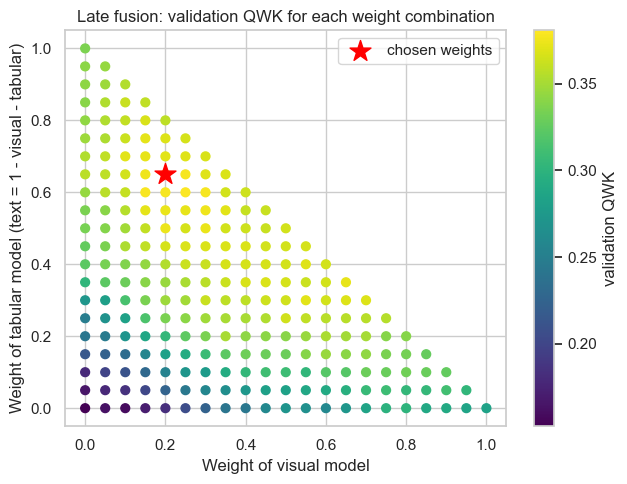

In [19]:
# Late fusion(Weight compare)
g = late.grid
rules = {
    "Best QWK (chosen)": g.sort_values(["QWK", "log loss"], ascending=[False, True]).iloc[0],
    "Best accuracy": g.sort_values(["accuracy", "log loss"], ascending=[False, True]).iloc[0],
    "Best log loss": g.sort_values("log loss").iloc[0],
}
cols = ["w_visual", "w_text", "w_tabular", "accuracy", "macro F1", "QWK", "log loss"]
print(pd.DataFrame(rules).T[cols].astype(float).round(3))

# Each grid point is one weight combination; the text weight is whatever is left over
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(g["w_visual"], g["w_tabular"], c=g["QWK"], cmap="viridis", s=40)
ax.scatter(late.weights[0], late.weights[2], marker="*", s=250, color="red", label="chosen weights")
plt.colorbar(sc, label="validation QWK")
ax.set(title="Late fusion: validation QWK for each weight combination",
       xlabel="Weight of visual model", ylabel="Weight of tabular model (text = 1 - visual - tabular)")
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
# Attention fusion: model and training
MODS = ["visual", "text", "tabular"]

class AttentionFusionNet(nn.Module):
    def __init__(self, dims, d=256, heads=4, dropout=0.3, n_classes=5):
        super().__init__()
        self.encoders = nn.ModuleList([
            nn.Sequential(nn.Linear(k, d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(dropout))
            for k in dims])
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(d)
        self.fuse = nn.Sequential(nn.Linear(len(dims) * d, d), nn.GELU(), nn.Dropout(dropout))
        self.out = nn.Linear(d, n_classes)

    def forward(self, xs, return_attn=False):
        tokens = torch.stack([enc(x) for enc, x in zip(self.encoders, xs)], dim=1)  # (B, 3, d)
        att, w = self.attn(tokens, tokens, tokens, need_weights=True, average_attn_weights=True)
        tokens = self.norm(tokens + att)                      # residual + LayerNorm
        logits = self.out(self.fuse(tokens.flatten(1)))
        return (logits, w) if return_attn else logits


class AttentionFusionClassifier:
    def __init__(self, d=256, heads=4, dropout=0.3, lr=1e-3, weight_decay=1e-2,
                 batch_size=64, max_epochs=100, patience=10):
        self.p = dict(d=d, heads=heads, dropout=dropout, lr=lr, weight_decay=weight_decay,
                      batch_size=batch_size, max_epochs=max_epochs, patience=patience)

    def _x(self, data, split):
        return [torch.tensor(data[m][split], dtype=torch.float32, device=DEVICE) for m in MODS]

    def fit(self, data, labels):
        p = self.p
        torch.manual_seed(SEED)
        np.random.seed(SEED)
        xtr, xva = self._x(data, "train"), self._x(data, "val")
        ytr = torch.tensor(labels["train"], dtype=torch.long, device=DEVICE)
        yva = torch.tensor(labels["val"], dtype=torch.long, device=DEVICE)

        self.model = AttentionFusionNet([x.shape[1] for x in xtr], p["d"], p["heads"], p["dropout"]).to(DEVICE)
        opt = torch.optim.AdamW(self.model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
        self.n_params = sum(t.numel() for t in self.model.parameters())

        self.history = []
        best_loss, best_state, best_epoch, wait = np.inf, None, 0, 0
        for epoch in range(1, p["max_epochs"] + 1):
            self.model.train()
            perm = torch.randperm(len(ytr))
            tr_loss = 0.0
            for i in range(0, len(perm), p["batch_size"]):
                idx = perm[i:i + p["batch_size"]].to(DEVICE)
                loss = F.cross_entropy(self.model([x[idx] for x in xtr]), ytr[idx])
                opt.zero_grad()
                loss.backward()
                opt.step()
                tr_loss += loss.item() * len(idx)
            self.model.eval()
            with torch.no_grad():
                logits = self.model(xva)
                va_loss = F.cross_entropy(logits, yva).item()
                va_acc = (logits.argmax(1) == yva).float().mean().item()
            self.history.append({"epoch": epoch, "train loss": tr_loss / len(ytr),
                                 "val loss": va_loss, "val acc": va_acc})
            if va_loss < best_loss:
                best_loss, best_epoch, wait = va_loss, epoch, 0
                best_state = {k: v.detach().clone() for k, v in self.model.state_dict().items()}
            else:
                wait += 1
                if wait >= p["patience"]:
                    break
        self.model.load_state_dict(best_state)
        self.best_epoch = best_epoch
        self.history = pd.DataFrame(self.history)
        return self

    def predict_proba(self, data, split):
        self.model.eval()
        xs = self._x(data, split)
        with torch.no_grad():
            out = [F.softmax(self.model([x[i:i + 1024] for x in xs]), dim=1).cpu().numpy()
                   for i in range(0, len(xs[0]), 1024)]
        return np.concatenate(out)

    def attention(self, data, split):
        self.model.eval()
        with torch.no_grad():
            _, w = self.model(self._x(data, split), return_attn=True)
        return w.mean(0).cpu().numpy()          # average over pets: (3, 3), row = query, column = key


t0 = time.time()
attn = AttentionFusionClassifier().fit(data, labels)
time_attn = time.time() - t0

print(f"device: {DEVICE} | epochs run: {len(attn.history)} | best epoch: {attn.best_epoch}")
print(f"parameters: {attn.n_params:,} | training time: {time_attn:.1f} s")
print(pd.Series(metrics(labels["val"], attn.predict_proba(data, "val"))).round(3))

device: mps | epochs run: 11 | best epoch: 1
parameters: 1,201,669 | training time: 6.8 s
accuracy       0.383
macro F1       0.287
weighted F1    0.352
QWK            0.326
log loss       1.348
dtype: float64


In [21]:
# Attention fusion: regularisation comparison (validation set)
configs = {
    "default: d=256, drop 0.3, lr 1e-3, wd 0.01": {},
    "d=64, drop 0.5, lr 3e-4, wd 0.01": dict(d=64, dropout=0.5, lr=3e-4, weight_decay=1e-2),
    "d=64, drop 0.5, lr 1e-4, wd 0.1": dict(d=64, dropout=0.5, lr=1e-4, weight_decay=1e-1),
    "d=32, drop 0.5, lr 1e-4, wd 0.1": dict(d=32, dropout=0.5, lr=1e-4, weight_decay=1e-1),
}

attn_models, attn_times, rows = {}, {}, []
for name, cfg in configs.items():
    t0 = time.time()
    m = AttentionFusionClassifier(**cfg).fit(data, labels)
    attn_times[name] = time.time() - t0
    attn_models[name] = m
    tr = pd.Series(metrics(labels["train"], m.predict_proba(data, "train")))
    va = pd.Series(metrics(labels["val"], m.predict_proba(data, "val")))
    rows.append({"config": name, "parameters": m.n_params, "best epoch": m.best_epoch,
                 "train acc": tr["accuracy"], "val acc": va["accuracy"],
                 "val QWK": va["QWK"], "val log loss": va["log loss"],
                 "time (s)": attn_times[name]})

attn_table = pd.DataFrame(rows).set_index("config")
print(attn_table.round(3))

# Choose by validation QWK (same primary metric as the late-fusion weights)
best_name = attn_table["val QWK"].idxmax()
attn, time_attn = attn_models[best_name], attn_times[best_name]
print("\nchosen:", best_name)

                                            parameters  best epoch  train acc  \
config                                                                          
default: d=256, drop 0.3, lr 1e-3, wd 0.01     1201669           1      0.492   
d=64, drop 0.5, lr 3e-4, wd 0.01                214405           3      0.496   
d=64, drop 0.5, lr 1e-4, wd 0.1                 214405           6      0.479   
d=32, drop 0.5, lr 1e-4, wd 0.1                 100037          10      0.494   

                                            val acc  val QWK  val log loss  \
config                                                                       
default: d=256, drop 0.3, lr 1e-3, wd 0.01    0.383    0.326         1.348   
d=64, drop 0.5, lr 3e-4, wd 0.01              0.394    0.332         1.357   
d=64, drop 0.5, lr 1e-4, wd 0.1               0.390    0.312         1.365   
d=32, drop 0.5, lr 1e-4, wd 0.1               0.381    0.309         1.368   

                                            

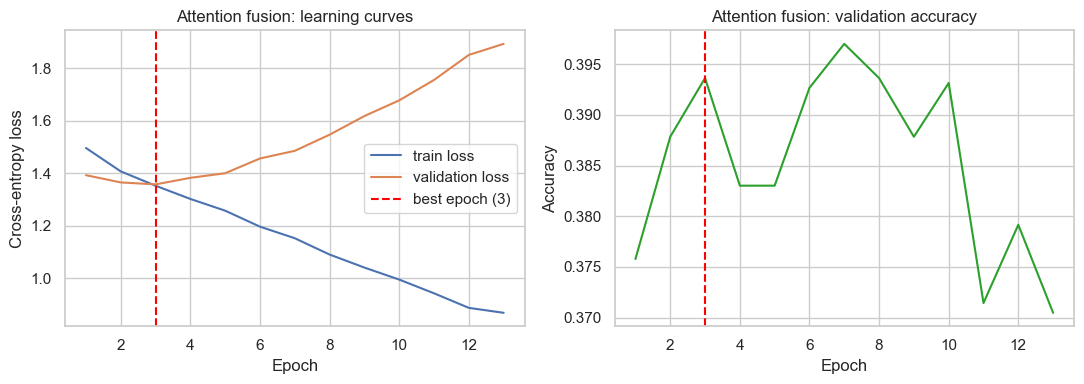

       accuracy  macro F1  weighted F1    QWK  log loss
train     0.496     0.375        0.467  0.484     1.210
val       0.394     0.290        0.369  0.332     1.357
                        accuracy  macro F1  weighted F1    QWK  log loss  \
Early fusion (XGBoost)     0.398     0.295        0.374  0.357     1.338   
Late fusion (XGBoost)      0.424     0.311        0.395  0.381     1.351   
Attention fusion (MLP)     0.394     0.290        0.369  0.332     1.357   

                        training time (s)  
Early fusion (XGBoost)             21.773  
Late fusion (XGBoost)              19.229  
Attention fusion (MLP)             10.722  
         visual   text  tabular
visual    0.333  0.334    0.333
text      0.335  0.327    0.337
tabular   0.334  0.336    0.329


In [22]:
# Attention fusion: learning curves, overfitting check and comparison
h = attn.history
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h["epoch"], h["train loss"], label="train loss")
ax[0].plot(h["epoch"], h["val loss"], label="validation loss")
ax[0].axvline(attn.best_epoch, color="red", linestyle="--", label=f"best epoch ({attn.best_epoch})")
ax[0].set(title="Attention fusion: learning curves", xlabel="Epoch", ylabel="Cross-entropy loss")
ax[0].legend()
ax[1].plot(h["epoch"], h["val acc"], color="tab:green")
ax[1].axvline(attn.best_epoch, color="red", linestyle="--")
ax[1].set(title="Attention fusion: validation accuracy", xlabel="Epoch", ylabel="Accuracy")
plt.tight_layout()
plt.show()

# Overfitting evidence: train vs validation for the attention model
gap = pd.DataFrame({s: metrics(labels[s], attn.predict_proba(data, s)) for s in ["train", "val"]}).T
print(gap.round(3))

# All three fusion methods on the validation set
cmp = pd.DataFrame({
    "Early fusion (XGBoost)": metrics(labels["val"], early.predict_proba(data, "val")),
    "Late fusion (XGBoost)": metrics(labels["val"], late.predict_proba(data, "val")),
    "Attention fusion (MLP)": metrics(labels["val"], attn.predict_proba(data, "val")),
}).T
cmp["training time (s)"] = [time_early, time_late, time_attn]
print(cmp.round(3))

# Average attention between modalities (row = query, column = key)
print(pd.DataFrame(attn.attention(data, "val"), index=MODS, columns=MODS).round(3))

## Section 3: Model Evaluation

### Task 5: Performance Metrics

Test set
                        accuracy  macro F1  weighted F1    QWK  log loss
Visual only (XGBoost)      0.361     0.259        0.324  0.302     1.402
Text only (XGBoost)        0.323     0.249        0.303  0.121     1.444
Tabular only (XGBoost)     0.379     0.289        0.357  0.339     1.353
Early fusion (XGBoost)     0.390     0.298        0.367  0.366     1.355
Late fusion (XGBoost)      0.397     0.296        0.367  0.363     1.354
Attention fusion (MLP)     0.388     0.285        0.355  0.354     1.365

accuracy by split
                        train    val   test
Visual only (XGBoost)   0.504  0.357  0.361
Text only (XGBoost)     0.518  0.339  0.323
Tabular only (XGBoost)  0.432  0.400  0.379
Early fusion (XGBoost)  0.559  0.398  0.390
Late fusion (XGBoost)   0.490  0.424  0.397
Attention fusion (MLP)  0.496  0.394  0.388

QWK by split
                        train    val   test
Visual only (XGBoost)   0.405  0.284  0.302
Text only (XGBoost)     0.359  0.153  0.121
Tabular

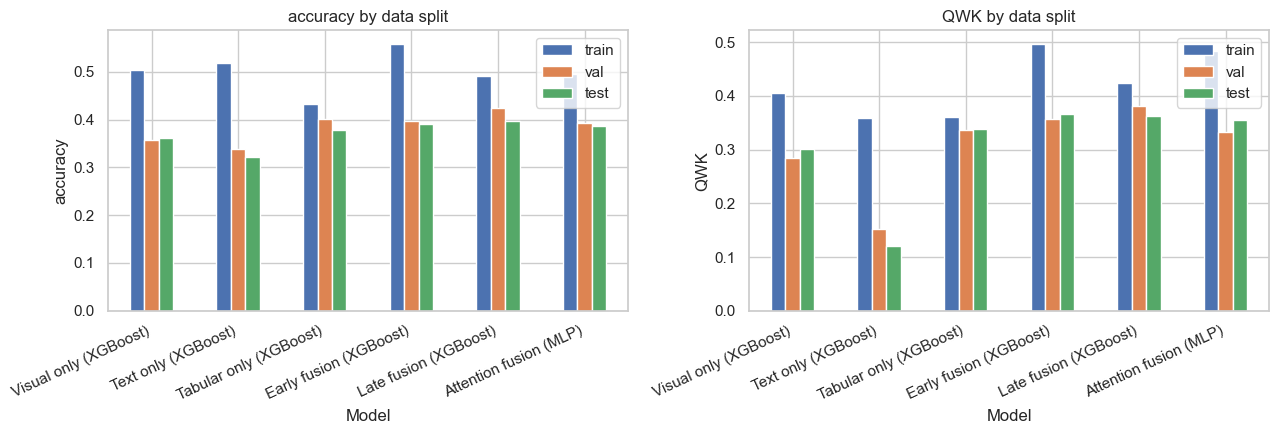

In [23]:
#Overall evaluation on the test set (first use of the test set)
def model_probas(split):
    p = late._probas(data, split)      # one probability matrix per modality
    out = {}
    for i, m in enumerate(MODS):
        out[f"{m.capitalize()} only (XGBoost)"] = p[m] if isinstance(p, dict) else p[i]
    out["Early fusion (XGBoost)"] = early.predict_proba(data, split)
    out["Late fusion (XGBoost)"] = late.predict_proba(data, split)
    out["Attention fusion (MLP)"] = attn.predict_proba(data, split)
    return out

probs = {s: model_probas(s) for s in ["train", "val", "test"]}
names = list(probs["test"].keys())

# Metrics for every model on every split
res = {s: pd.DataFrame({n: metrics(labels[s], probs[s][n]) for n in names}).T for s in probs}

print("Test set")
print(res["test"].round(3))

# Generalisation gap: same metric across train / val / test
for k in ["accuracy", "QWK"]:
    print(f"\n{k} by split")
    print(pd.DataFrame({s: res[s][k] for s in res}).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, k in zip(ax, ["accuracy", "QWK"]):
    pd.DataFrame({s: res[s][k] for s in res}).plot.bar(ax=a, rot=25)
    a.set(title=f"{k} by data split", xlabel="Model", ylabel=k)
    plt.setp(a.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

Test-set support per class: {0: 60, 1: 489, 2: 651, 3: 528, 4: 599}

Per-class recall
model  Visual only (XGBoost)  Text only (XGBoost)  Tabular only (XGBoost)  \
class                                                                       
0                      0.000                0.017                   0.000   
1                      0.284                0.149                   0.366   
2                      0.413                0.359                   0.398   
3                      0.072                0.222                   0.144   
4                      0.659                0.544                   0.614   

model  Early fusion (XGBoost)  Late fusion (XGBoost)  Attention fusion (MLP)  
class                                                                         
0                       0.000                  0.000                   0.000  
1                       0.331                  0.346                   0.350  
2                       0.389                  0.452      

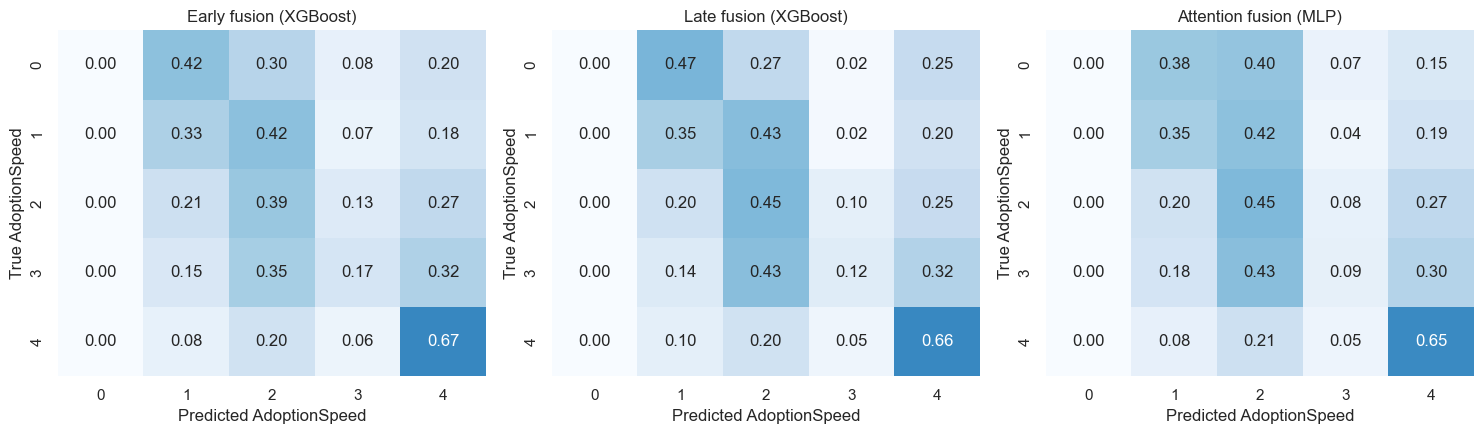

In [24]:
# Per-class results and confusion matrices on the test set
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

y_test = np.asarray(labels["test"])
rows = []
for n in names:
    pred = probs["test"][n].argmax(1)
    p, r, f, s = precision_recall_fscore_support(y_test, pred, labels=range(5), zero_division=0)
    for c in range(5):
        rows.append({"model": n, "class": c, "precision": p[c], "recall": r[c], "F1": f[c], "support": s[c]})
pc = pd.DataFrame(rows)

print("Test-set support per class:", pc[pc["model"] == names[0]].set_index("class")["support"].astype(int).to_dict())
for k in ["recall", "F1"]:
    print(f"\nPer-class {k}")
    print(pc.pivot(index="class", columns="model", values=k)[names].round(3))

# Row-normalised confusion matrices of the three fusion methods
fusion = ["Early fusion (XGBoost)", "Late fusion (XGBoost)", "Attention fusion (MLP)"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, n in zip(ax, fusion):
    cm = confusion_matrix(y_test, probs["test"][n].argmax(1), labels=range(5), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a)
    a.set(title=n, xlabel="Predicted AdoptionSpeed", ylabel="True AdoptionSpeed")
plt.tight_layout()
plt.show()

### Task 6: Efficiency Analysis, Error Analysis and Comparative Analysis

In [25]:
# Efficiency of the three fusion methods
n_pets, n_test = len(df), len(y_test)
ext = {m: extract_time[m] for m in ["visual", "text", "tabular"]}
print("Feature extraction (s):", {k: round(v, 1) for k, v in ext.items()},
      "| per pet (ms):", {k: round(v / n_pets * 1000, 2) for k, v in ext.items()})

def time_predict(f, reps=3):
    f()                                    # warm-up
    t0 = time.time()
    for _ in range(reps):
        f()
    return (time.time() - t0) / reps

fusion_models = {
    "Early fusion (XGBoost)": (early, time_early),
    "Late fusion (XGBoost)": (late, time_late),
    "Attention fusion (MLP)": (attn, time_attn),
}
rows = []
for n, (mdl, t_train) in fusion_models.items():
    t_inf = time_predict(lambda: mdl.predict_proba(data, "test"))
    rows.append({"method": n,
                 "extraction (s)": sum(ext.values()),
                 "training (s)": t_train,
                 "total (s)": sum(ext.values()) + t_train,
                 "classifier inference (ms per 1000 pets)": t_inf / n_test * 1e6})
eff = pd.DataFrame(rows).set_index("method")
print(eff.round(1))
print("Attention parameters:", f"{attn.n_params:,}")

Feature extraction (s): {'visual': 52.5, 'text': 107.8, 'tabular': 0.0} | per pet (ms): {'visual': 3.59, 'text': 7.36, 'tabular': 0.0}
                        extraction (s)  training (s)  total (s)  \
method                                                            
Early fusion (XGBoost)           160.3          21.8      182.1   
Late fusion (XGBoost)            160.3          19.2      179.6   
Attention fusion (MLP)           160.3          10.7      171.1   

                        classifier inference (ms per 1000 pets)  
method                                                           
Early fusion (XGBoost)                                      1.7  
Late fusion (XGBoost)                                       2.1  
Attention fusion (MLP)                                      2.3  
Attention parameters: 214,405


                       accuracy                  QWK              
                           test  lower  upper   test  lower  upper
Visual only (XGBoost)     0.361  0.341  0.382  0.302  0.265  0.340
Text only (XGBoost)       0.323  0.302  0.342  0.121  0.081  0.157
Tabular only (XGBoost)    0.379  0.361  0.399  0.339  0.303  0.375
Early fusion (XGBoost)    0.390  0.369  0.411  0.366  0.331  0.402
Late fusion (XGBoost)     0.397  0.377  0.416  0.363  0.327  0.401
Attention fusion (MLP)    0.388  0.367  0.408  0.354  0.316  0.390
                                          A - B   metric  difference  95% CI low  95% CI high  includes 0
 Late fusion (XGBoost) - Tabular only (XGBoost) accuracy       0.018       0.008        0.028       False
 Late fusion (XGBoost) - Tabular only (XGBoost)      QWK       0.024       0.007        0.042       False
Early fusion (XGBoost) - Tabular only (XGBoost) accuracy       0.011      -0.008        0.029        True
Early fusion (XGBoost) - Tabular only (X

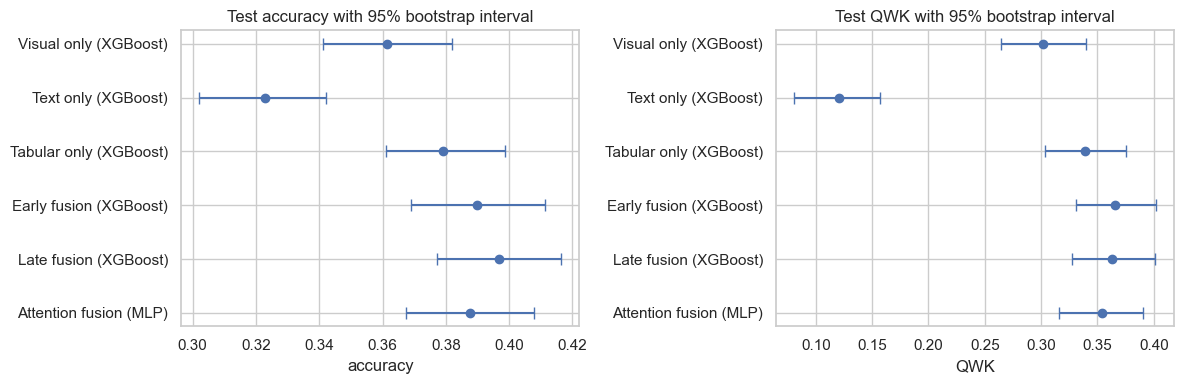

In [26]:
# Bootstrap confidence intervals on the test set
rng = np.random.default_rng(SEED)
B, n = 1000, len(y_test)
preds = {k: probs["test"][k].argmax(1) for k in names}
boot = {k: {"accuracy": [], "QWK": []} for k in names}
for _ in range(B):
    idx = rng.integers(0, n, n)
    yt = y_test[idx]
    for k in names:
        yp = preds[k][idx]
        boot[k]["accuracy"].append((yp == yt).mean())
        boot[k]["QWK"].append(cohen_kappa_score(yt, yp, weights="quadratic"))
boot = {k: {m: np.array(v) for m, v in d.items()} for k, d in boot.items()}

ci = pd.DataFrame({
    (m, s): [res["test"].loc[k, m] if s == "test" else
             (np.percentile(boot[k][m], 2.5) if s == "lower" else np.percentile(boot[k][m], 97.5))
             for k in names]
    for m in ["accuracy", "QWK"] for s in ["test", "lower", "upper"]}, index=names)
print(ci.round(3))

# Paired differences (same resamples for both models)
pairs = [("Late fusion (XGBoost)", "Tabular only (XGBoost)"),
         ("Early fusion (XGBoost)", "Tabular only (XGBoost)"),
         ("Attention fusion (MLP)", "Tabular only (XGBoost)"),
         ("Late fusion (XGBoost)", "Early fusion (XGBoost)")]
rows = []
for a, b in pairs:
    for m in ["accuracy", "QWK"]:
        d = boot[a][m] - boot[b][m]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"A - B": f"{a} - {b}", "metric": m, "difference": res["test"].loc[a, m] - res["test"].loc[b, m],
                     "95% CI low": lo, "95% CI high": hi, "includes 0": lo <= 0 <= hi})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Figure: test metrics with 95% intervals
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, m in zip(ax, ["accuracy", "QWK"]):
    est = ci[(m, "test")].values
    err = np.vstack([est - ci[(m, "lower")].values, ci[(m, "upper")].values - est])
    a_.errorbar(est, range(len(names)), xerr=err, fmt="o", capsize=4)
    a_.set_yticks(range(len(names)))
    a_.set_yticklabels(names)
    a_.set(title=f"Test {m} with 95% bootstrap interval", xlabel=m)
    a_.invert_yaxis()
plt.tight_layout()
plt.show()

           attribute            group    n  accuracy   QWK  mean true  mean predicted
                 All         all pets 2327     0.397 0.363      2.480           2.595
         Animal type              Dog 1319     0.408 0.370      2.575           2.759
         Animal type              Cat 1008     0.382 0.334      2.355           2.380
  Description length            short  798     0.372 0.385      2.434           2.475
  Description length             long  773     0.402 0.373      2.470           2.668
  Description length           medium  756     0.417 0.326      2.540           2.647
Description language <= 10% non-ASCII 2312     0.396 0.361      2.478           2.594
Description language  > 10% non-ASCII   15     0.533 0.600      2.800           2.667
    Number of photos              2-4 1089     0.406 0.368      2.479           2.598
    Number of photos               5+  760     0.397 0.350      2.416           2.562
    Number of photos       1 or fewer  478     0.374 0

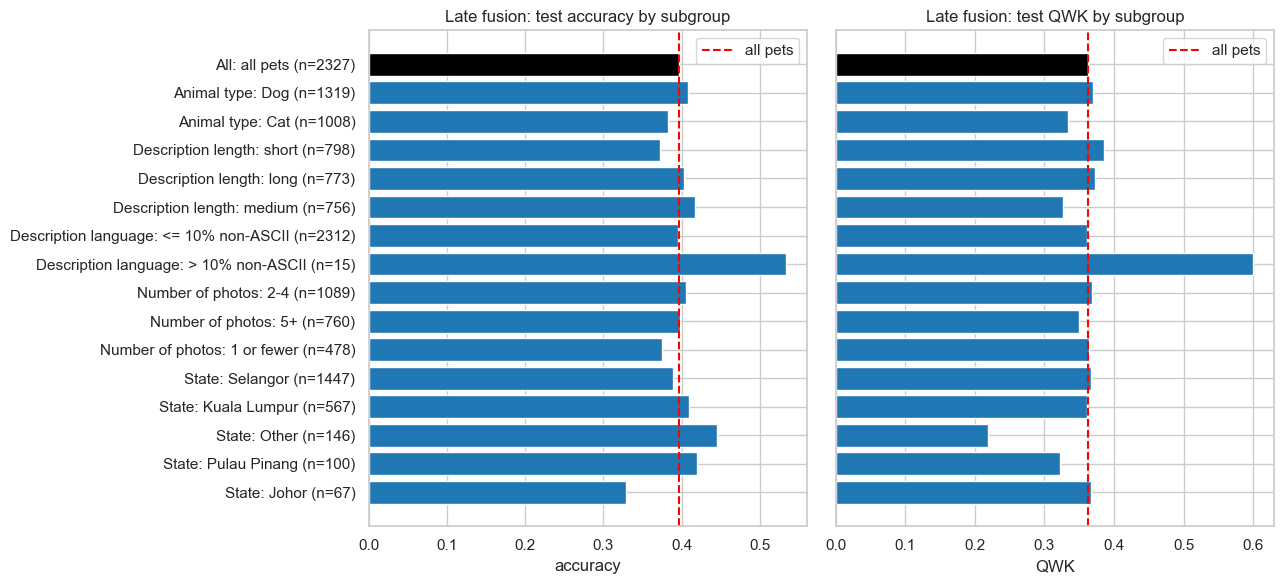

In [27]:
# Subgroup performance of late fusion on the test set
test_df = df[df["split"] == "test"].reset_index(drop=True)
assert len(test_df) == len(y_test), "test rows are not aligned with the test features"

state_files = [p for p in DATA.rglob("*.csv") if p.name.lower().replace("_", "") == "statelabels.csv"]
if state_files:
    st = pd.read_csv(state_files[0]).set_index("StateID")["StateName"]
    test_df["state_name"] = test_df["State"].map(st).fillna(test_df["State"].astype(str))
else:
    test_df["state_name"] = test_df["State"].astype(str)
top_states = test_df["state_name"].value_counts().head(4).index

groups = {
    "Animal type": test_df["Type"].map({1: "Dog", 2: "Cat"}),
    "Description length": pd.qcut(test_df["desc_words"], 3, labels=["short", "medium", "long"]),
    "Description language": np.where(test_df["non_ascii_share"] > 0.1, "> 10% non-ASCII", "<= 10% non-ASCII"),
    "Number of photos": pd.cut(test_df["PhotoAmt"], [-1, 1, 4, np.inf], labels=["1 or fewer", "2-4", "5+"]),
    "State": test_df["state_name"].where(test_df["state_name"].isin(top_states), "Other"),
}

pred = probs["test"]["Late fusion (XGBoost)"].argmax(1)

def row(attr, level, mask):
    yt, yp = y_test[mask], pred[mask]
    return {"attribute": attr, "group": level, "n": int(mask.sum()),
            "accuracy": (yt == yp).mean(),
            "QWK": cohen_kappa_score(yt, yp, weights="quadratic"),
            "mean true": yt.mean(), "mean predicted": yp.mean()}

rows = [row("All", "all pets", np.ones(len(y_test), dtype=bool))]
for attr, g in groups.items():
    g = np.asarray(pd.Series(g).astype(str))
    for level in pd.Series(g).value_counts().index:
        rows.append(row(attr, level, g == level))
sub = pd.DataFrame(rows)
print(sub.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
labels_ = [f"{a}: {g} (n={n})" for a, g, n in zip(sub["attribute"], sub["group"], sub["n"])]
for a_, m in zip(ax, ["accuracy", "QWK"]):
    a_.barh(range(len(sub)), sub[m], color=["black"] + ["tab:blue"] * (len(sub) - 1))
    a_.axvline(sub[m].iloc[0], color="red", linestyle="--", label="all pets")
    a_.set(title=f"Late fusion: test {m} by subgroup", xlabel=m)
    a_.legend()
ax[0].set_yticks(range(len(sub)))
ax[0].set_yticklabels(labels_)
ax[0].invert_yaxis()
plt.tight_layout()
plt.show()

Validation set
       accuracy  macro F1  weighted F1    QWK  log loss  recall class 0  \
alpha                                                                     
0.00      0.424     0.311        0.395  0.381     1.351           0.000   
0.25      0.420     0.315        0.396  0.381     1.357           0.000   
0.50      0.409     0.320        0.392  0.369     1.376           0.018   
0.75      0.398     0.326        0.388  0.359     1.417           0.071   
1.00      0.344     0.303        0.357  0.302     1.490           0.375   

       recall class 3  share predicted as 0  
alpha                                        
0.00            0.161                 0.000  
0.25            0.184                 0.000  
0.50            0.219                 0.003  
0.75            0.249                 0.027  
1.00            0.258                 0.203  

chosen alpha (best validation macro F1): 0.75


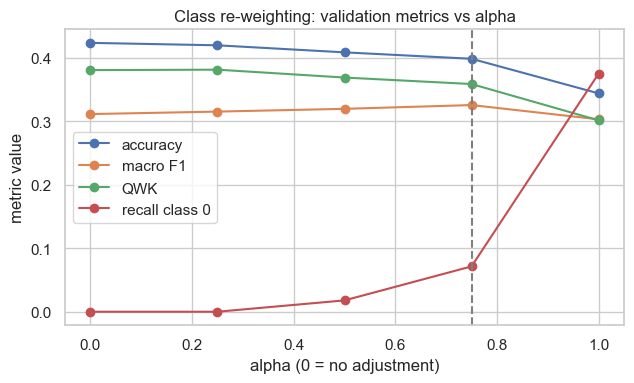


Test set
                         accuracy  macro F1  weighted F1    QWK  log loss  \
no adjustment (alpha=0)     0.397     0.296        0.367  0.363     1.354   
adjusted (alpha=0.75)       0.381     0.321        0.370  0.347     1.419   

                         recall class 0  recall class 3  share predicted as 0  
no adjustment (alpha=0)           0.000           0.119                 0.000  
adjusted (alpha=0.75)             0.117           0.214                 0.035  


In [28]:
# Bias mitigation: post-hoc class re-weighting of the late-fusion probabilities
prior = np.bincount(np.asarray(labels["train"]), minlength=5) / len(labels["train"])

def adjust(proba, alpha):
    q = proba * prior ** (-alpha)
    return q / q.sum(1, keepdims=True)

def evaluate(split, alpha):
    y = np.asarray(labels[split])
    proba = adjust(probs[split]["Late fusion (XGBoost)"], alpha)
    pred = proba.argmax(1)
    m = pd.Series(metrics(y, proba))
    m["recall class 0"] = ((pred == 0) & (y == 0)).sum() / (y == 0).sum()
    m["recall class 3"] = ((pred == 3) & (y == 3)).sum() / (y == 3).sum()
    m["share predicted as 0"] = (pred == 0).mean()
    return m

alphas = [0, 0.25, 0.5, 0.75, 1.0]
val_tab = pd.DataFrame({a: evaluate("val", a) for a in alphas}).T
val_tab.index.name = "alpha"
print("Validation set")
print(val_tab.round(3))

best_alpha = val_tab["macro F1"].idxmax()
print("\nchosen alpha (best validation macro F1):", best_alpha)

fig, ax = plt.subplots(figsize=(6.5, 4))
for c in ["accuracy", "macro F1", "QWK", "recall class 0"]:
    ax.plot(val_tab.index, val_tab[c], marker="o", label=c)
ax.axvline(best_alpha, color="grey", linestyle="--")
ax.set(title="Class re-weighting: validation metrics vs alpha", xlabel="alpha (0 = no adjustment)", ylabel="metric value")
ax.legend()
plt.tight_layout()
plt.show()

test_tab = pd.DataFrame({"no adjustment (alpha=0)": evaluate("test", 0),
                         f"adjusted (alpha={best_alpha})": evaluate("test", best_alpha)}).T
print("\nTest set")
print(test_tab.round(3))

In [29]:
# Final comparison table (test set)
summary = res["test"][["accuracy", "macro F1", "QWK", "log loss"]].copy()
summary["accuracy 95% CI"] = [f"[{ci.loc[n, ('accuracy', 'lower')]:.3f}, {ci.loc[n, ('accuracy', 'upper')]:.3f}]" for n in summary.index]
summary["QWK 95% CI"] = [f"[{ci.loc[n, ('QWK', 'lower')]:.3f}, {ci.loc[n, ('QWK', 'upper')]:.3f}]" for n in summary.index]
summary["train - test accuracy"] = res["train"]["accuracy"] - res["test"]["accuracy"]
summary["recall class 0"] = pc[pc["class"] == 0].set_index("model")["recall"]
summary["total time (s)"] = eff["total (s)"]       # extraction + training; fusion methods only

Path("results").mkdir(exist_ok=True)
summary.to_csv("results/test_summary.csv")
print(summary.round(3).to_string())

                        accuracy  macro F1    QWK  log loss accuracy 95% CI      QWK 95% CI  train - test accuracy  recall class 0  total time (s)
Visual only (XGBoost)      0.361     0.259  0.302     1.402  [0.341, 0.382]  [0.265, 0.340]                  0.142           0.000             NaN
Text only (XGBoost)        0.323     0.249  0.121     1.444  [0.302, 0.342]  [0.081, 0.157]                  0.195           0.017             NaN
Tabular only (XGBoost)     0.379     0.289  0.339     1.353  [0.361, 0.399]  [0.303, 0.375]                  0.053           0.000             NaN
Early fusion (XGBoost)     0.390     0.298  0.366     1.355  [0.369, 0.411]  [0.331, 0.402]                  0.169           0.000         182.114
Late fusion (XGBoost)      0.397     0.296  0.363     1.354  [0.377, 0.416]  [0.327, 0.401]                  0.094           0.000         179.570
Attention fusion (MLP)     0.388     0.285  0.354     1.365  [0.367, 0.408]  [0.316, 0.390]                  0.108    